# Espera de Olist: tramos, promesa y nota

Objetivo de trabajo: explorar un conjunto de datos reales, identificar sus características y posibles problemas de calidad, realizar las transformaciones necesarias y construir visualizaciones que permitan descubrir patrones, relaciones y comportamientos relevantes.

**Pregunta.** ¿De qué está hecha la espera del cliente, qué tan holgada es la fecha prometida y cuál de las dos se ve en la reseña?

El conjunto es el [Brazilian E-Commerce Public Dataset](https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce) de Olist: pedidos reales de 2016 a 2018. 

Resultados:

1. La espera se parte en aprobación del pago, entrega del vendedor al transportista y tránsito. El tránsito concentra la varianza y casi toda la diferencia entre notas bajas y altas.
2. La fecha prometida es holgada: cerca del 92% de los paquetes llega antes de ese día, cerca del 7% llega tarde y el error absoluto medio ronda 13 días.
3. La nota acompaña a la espera y al atraso mucho más que al flete o al precio. Una entrega de muchos días que cumple la promesa conserva una nota alta; una que se pasa del día prometido, no.
4. En el paro de camioneros del 21 al 30 de mayo de 2018 la fecha prometida se alargó más que la espera observada, y el porcentaje de tardanzas bajó.

Las cifras de abajo salen de este extracto. En `eda_pedidos` encontramos que la fecha prometida está guardada a medianoche y que una espera larga no es lo mismo que una tardanza. Aquí la tardanza es de calendario, y la espera se abre en tramos.

**Archivos.** `olist_orders_dataset.csv`, `olist_customers_dataset.csv`, `olist_order_reviews_dataset.csv`, `olist_order_items_dataset.csv` y `olist_sellers_dataset.csv`.


## 1. Lectura

<!-- Busca los CSV en `OLIST_DATA_DIR`, en `~/projects/work-at-olist-data/datasets` y en carpetas hermanas del directorio de trabajo. -->

In [15]:
# dependencias
from pathlib import Path
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from scipy import stats

In [16]:
# configuraciones
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 30)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.28,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.labelsize": 11,
})

In [17]:
# helpers
FIGURAS = []
#
def figura(titulo, xlabel, ylabel, ancho=9, alto=4.6):
    fig, ax = plt.subplots(figsize=(ancho, alto))
    ax.set_title(titulo)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    FIGURAS.append(titulo)
    return fig, ax
#
def coef(metodo, x, y):
    resultado = metodo(x, y)
    return float(getattr(resultado, "statistic", resultado[0]))
# locate data
def localizar_directorio(requeridos):
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())
    candidatos.append(Path("~/projects/work-at-olist-data/datasets").expanduser())
    ubicacion = Path.cwd().resolve()
    for base_dir in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base_dir / "work-at-olist-data" / "datasets",
            base_dir / "datasets",
            base_dir.parent / "work-at-olist-data" / "datasets",
        ])
    vistos = set()
    for ruta in candidatos:
        clave = str(ruta)
        if clave in vistos:
            continue
        vistos.add(clave)
        if all((ruta / nombre).is_file() for nombre in requeridos):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV requeridos. Define OLIST_DATA_DIR o clona "
        "https://github.com/olist/work-at-olist-data junto al proyecto."
    )

In [18]:
# data paths
REQUERIDOS = (
    "olist_orders_dataset.csv",
    "olist_customers_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_sellers_dataset.csv",
)
DATA_DIR = localizar_directorio(REQUERIDOS)
print("Directorio:", DATA_DIR)

Directorio: /home/alberto/projects/work-at-olist-data/datasets


In [19]:
## load data
# date columns
FECHAS_PEDIDO = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
#
pedidos = pd.read_csv(
    DATA_DIR / "olist_orders_dataset.csv",
    dtype={"order_id": "string", "customer_id": "string", "order_status": "string"},
    parse_dates=FECHAS_PEDIDO,
    encoding="utf-8-sig",
)
clientes = pd.read_csv(
    DATA_DIR / "olist_customers_dataset.csv",
    usecols=["customer_id", "customer_state"],
    dtype={"customer_id": "string", "customer_state": "string"},
    encoding="utf-8-sig",
)
resenas = pd.read_csv(
    DATA_DIR / "olist_order_reviews_dataset.csv",
    usecols=["review_id", "order_id", "review_score"],
    dtype={"review_id": "string", "order_id": "string"},
    encoding="utf-8-sig",
)
articulos = pd.read_csv(
    DATA_DIR / "olist_order_items_dataset.csv",
    dtype={"order_id": "string", "order_item_id": "string", "product_id": "string", "seller_id": "string"},
    parse_dates=["shipping_limit_date"],
    encoding="utf-8-sig",
)
vendedores = pd.read_csv(
    DATA_DIR / "olist_sellers_dataset.csv",
    usecols=["seller_id", "seller_state"],
    dtype={"seller_id": "string", "seller_state": "string"},
    encoding="utf-8-sig",
)

In [20]:
# observaciones
print(f"pedidos:    {len(pedidos):,}")
print(f"reseñas:    {len(resenas):,}")
print(f"artículos:  {len(articulos):,}")
print(f"vendedores: {len(vendedores):,}")
# vistazo
display(pedidos.head(3))

pedidos:    99,441
reseñas:    99,224
artículos:  112,650
vendedores: 3,095


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


## 2. Calidad de datos, antes de medir los retrazos

Una fila de pedidos es un pedido. Una fila de artículos es una línea, y una fila de reseñas no es única por pedido: unirlas sin agregar multiplicaría la espera y el flete. La fecha prometida trae hora 00:00 en todos los pedidos; el límite de despacho del vendedor trae hora real. Comparar el reloj de la entrega con la medianoche del día prometido marca como tarde un paquete que llegó durante ese día.

Tampoco se rellena una entrega ausente. En un pedido no entregado el hueco es estructural. Unas pocas fechas están invertidas: el transportista queda antes de la aprobación, o el cliente antes del transportista. Esas filas se conservan y se apartan solo del reparto por tramos. Las esperas de varios meses se conservan en las tasas y se dejan fuera de los histogramas, que si no dedican el último intervalo a la cola.


In [21]:
entregado = pedidos["order_status"].eq("delivered")
tiene_cliente = pedidos["order_delivered_customer_date"].notna()
tiene_carrier = pedidos["order_delivered_carrier_date"].notna()
tiene_aprobacion = pedidos["order_approved_at"].notna()
compra = pedidos["order_purchase_timestamp"]

casos = pd.DataFrame({
    "caso": [
        "Sin fecha de entrega al cliente",
        "Marcados delivered y sin esa fecha",
        "No marcados delivered y con esa fecha",
        "Sin aprobación del pago",
        "Sin entrega al transportista",
        "Transportista anterior a la compra",
        "Transportista anterior a la aprobación",
        "Cliente anterior al transportista",
        "Promesa con hora distinta de 00:00",
        "Límite de despacho con hora distinta de 00:00",
    ],
    "filas": [
        int((~tiene_cliente).sum()),
        int((entregado & ~tiene_cliente).sum()),
        int((~entregado & tiene_cliente).sum()),
        int((~tiene_aprobacion).sum()),
        int((~tiene_carrier).sum()),
        int((tiene_carrier & pedidos["order_delivered_carrier_date"].lt(compra)).sum()),
        int((tiene_carrier & tiene_aprobacion & pedidos["order_delivered_carrier_date"].lt(pedidos["order_approved_at"])).sum()),
        int((tiene_cliente & tiene_carrier & pedidos["order_delivered_customer_date"].lt(pedidos["order_delivered_carrier_date"])).sum()),
        int(pedidos["order_estimated_delivery_date"].dt.hour.ne(0).sum()),
        int(articulos["shipping_limit_date"].dt.hour.ne(0).sum()),
    ],
})
display(casos)
# Artículos: 112,650 filas para 98,666 pedidos. Pedidos sin ninguna línea: 775. 
# Reseñas: 99,224 filas para 98,673 pedidos; 202 pedidos traen más de una nota distinta. 
# Esos pedidos se apartan del cruce con la nota y se quedan en el resto del cuaderno.

,caso,filas
0,Sin fecha de entrega al cliente,2965
1,Marcados delivered y sin esa fecha,8
2,No marcados delivered y con esa fecha,6
3,Sin aprobación del pago,160
4,Sin entrega al transportista,1783
5,Transportista anterior a la compra,166
6,Transportista anterior a la aprobación,1359
7,Cliente anterior al transportista,23
8,Promesa con hora distinta de 00:00,0
9,Límite de despacho con hora distinta de 00:00,110247


## 3. Transformaciones

La espera es el tiempo desde la compra hasta la entrega al cliente, en días, y solo se calcula cuando esa entrega existe. Los tramos usan las mismas dos marcas de tiempo:

- aprobación: de la compra a `order_approved_at`;
- vendedor: de la aprobación a `order_delivered_carrier_date`;
- tránsito: del transportista a `order_delivered_customer_date`.

La promesa y la holgura comparan días. `dias_prometidos` es el día prometido menos el día de la compra. `holgura_dias` es el día prometido menos el día de entrega: positivo si el paquete llegó antes, cero si llegó ese día, negativo si llegó después. `tarde` es la holgura negativa.

El precio y el flete se suman por pedido. El límite de despacho del pedido es el máximo de sus items: el pedido no está completo para el transportista antes del último item. El estado del vendedor se conserva solo cuando todas los items comparten uno. La reseña se conserva cuando el pedido tiene una sola reseña distinta, aunque tenga más de una fila de reseña.

In [ ]:
notas = resenas.groupby("order_id", as_index=False).agg(
    n_resenas=("review_score", "size"),
    n_notas=("review_score", "nunique"),
    nota=("review_score", "first"),
)
lineas = articulos.merge(vendedores, on="seller_id", how="left", validate="many_to_one")
estado = lineas.groupby("order_id", as_index=False).agg(
    n_estados_vendedor=("seller_state", "nunique"),
    estado_vendedor=("seller_state", "first"),
)
estado.loc[estado["n_estados_vendedor"].ne(1), "estado_vendedor"] = pd.NA
por_articulo = articulos.groupby("order_id", as_index=False).agg(
    n_articulos=("order_item_id", "size"),
    precio=("price", "sum"),
    flete=("freight_value", "sum"),
    n_vendedores=("seller_id", "nunique"),
    limite_despacho=("shipping_limit_date", "max"),
).merge(estado, on="order_id", how="left", validate="one_to_one")

base = (
    pedidos.merge(clientes, on="customer_id", how="left", validate="many_to_one")
    .merge(notas, on="order_id", how="left", validate="one_to_one")
    .merge(por_articulo, on="order_id", how="left", validate="one_to_one")
)
assert len(base) == len(pedidos)

con = base.loc[
    base["order_delivered_customer_date"].notna() & base["order_estimated_delivery_date"].notna()
].copy()
dia = 86400
con["espera_dias"] = (
    con["order_delivered_customer_date"] - con["order_purchase_timestamp"]
).dt.total_seconds() / dia
con["tramo_aprobacion"] = (
    con["order_approved_at"] - con["order_purchase_timestamp"]
).dt.total_seconds() / dia
con["tramo_vendedor"] = (
    con["order_delivered_carrier_date"] - con["order_approved_at"]
).dt.total_seconds() / dia
con["tramo_transito"] = (
    con["order_delivered_customer_date"] - con["order_delivered_carrier_date"]
).dt.total_seconds() / dia
con["dias_prometidos"] = (
    con["order_estimated_delivery_date"].dt.normalize() - con["order_purchase_timestamp"].dt.normalize()
).dt.days
con["holgura_dias"] = (
    con["order_estimated_delivery_date"].dt.normalize() - con["order_delivered_customer_date"].dt.normalize()
).dt.days
con["tarde"] = con["holgura_dias"].lt(0)
con["tramos_validos"] = (
    con["tramo_aprobacion"].ge(0) & con["tramo_vendedor"].ge(0) & con["tramo_transito"].ge(0)
)

REGION = {
    "AC": "Norte", "AP": "Norte", "AM": "Norte", "PA": "Norte", "RO": "Norte", "RR": "Norte", "TO": "Norte",
    "AL": "Nordeste", "BA": "Nordeste", "CE": "Nordeste", "MA": "Nordeste", "PB": "Nordeste",
    "PE": "Nordeste", "PI": "Nordeste", "RN": "Nordeste", "SE": "Nordeste",
    "DF": "Centro-Oeste", "GO": "Centro-Oeste", "MT": "Centro-Oeste", "MS": "Centro-Oeste",
    "ES": "Sudeste", "MG": "Sudeste", "RJ": "Sudeste", "SP": "Sudeste",
    "PR": "Sul", "RS": "Sul", "SC": "Sul",
}
con["region"] = con["customer_state"].map(REGION)

columnas = [
    "order_id", "customer_state", "espera_dias", "tramo_aprobacion", "tramo_vendedor",
    "tramo_transito", "dias_prometidos", "holgura_dias", "tarde", "nota", "flete",
]
display(con[columnas].head(3))
display(con[["espera_dias", "tramo_aprobacion", "tramo_vendedor", "tramo_transito", "dias_prometidos", "holgura_dias"]].describe().T.round(3))
# 96,476 pedidos tienen fecha de entrega y fecha prometida. 95,088 tienen además los tres tramos en orden cronológico.
# El resto permanece en la tabla y sale solo del reparto por tramos. La mediana de espera es 10.2 días y la de la promesa es 24.

,order_id,customer_state,espera_dias,tramo_aprobacion,tramo_vendedor,tramo_transito,dias_prometidos,holgura_dias,tarde,nota,flete
0,e481f51cbdc54678b7cc49136f2d6af7,SP,8.436574,0.007431,2.366493,6.062650,16,8,False,4.0,8.72
1,53cdb2fc8bc7dce0b6741e2150273451,BA,13.782037,1.279745,0.462882,12.039410,20,6,False,4.0,22.76
2,47770eb9100c2d0c44946d9cf07ec65d,GO,9.394213,0.011505,0.204595,9.178113,27,18,False,5.0,19.22


,count,mean,std,min,25%,50%,75%,max
espera_dias,96476.0,12.559,9.547,0.533,6.766,10.218,15.720,209.629
tramo_aprobacion,96462.0,0.428,0.856,0.000,0.009,0.014,0.605,30.893
tramo_vendedor,96461.0,2.799,3.538,-171.219,0.874,1.816,3.575,125.763
tramo_transito,96475.0,9.331,8.760,-16.096,4.100,7.100,12.029,205.191
dias_prometidos,96476.0,24.374,8.761,3.000,19.000,24.000,29.000,156.000
holgura_dias,96476.0,11.877,10.184,-188.000,7.000,12.000,17.000,147.000


## 4. Dónde vive la espera

Las medias de los tres tramos suman la espera media, porque cada tramo es un pedazo del mismo intervalo. Las medianas no tienen por qué sumar la mediana: la aprobación es casi inmediata para la mitad de los pedidos y tiene una cola que le sube la media. El histograma corta en el percentil 99 para que esa cola no fije la escala; los pedidos cortados siguen dentro de las medias, las medianas y las tasas.


,media,mediana,parte de la varianza
Aprobación del pago,0.402,0.014,0.007
Vendedor al transportista,2.852,1.849,0.135
Transportista al cliente,9.364,7.110,0.858


Entre **95,088** pedidos con tramos en orden, la media de espera es **12.6** días y la suma de las medias de los tramos es **12.6**. La mediana de la aprobación es **20** minutos; su media es **9.7** horas. Notas 1 o 2 frente a notas 4 o 5, en **12,078** y **74,386** pedidos: la espera media difiere en **9.2** días, y el tránsito aporta **83%** de esa diferencia.

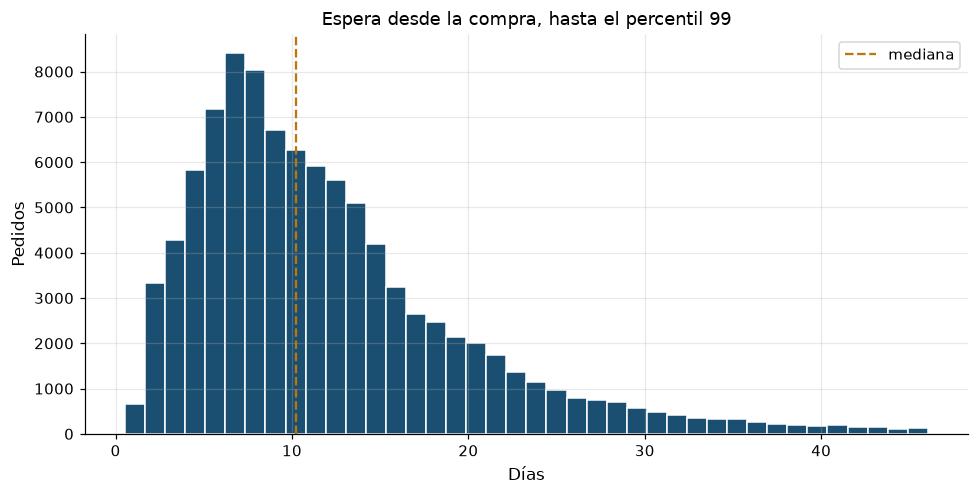

**965** pedidos superan el percentil 99 (46 días) y quedan fuera del histograma.

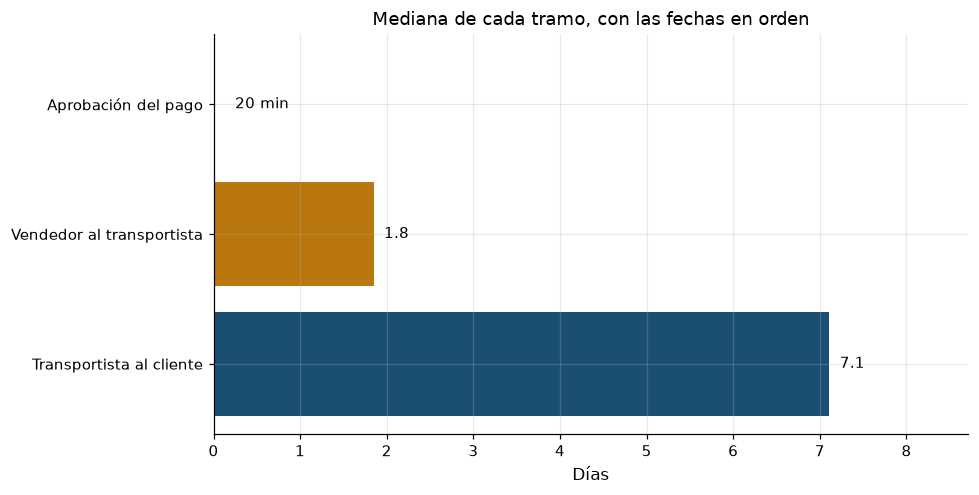

In [ ]:
validos = con.loc[con["tramos_validos"]].copy()
TRAMOS = ["tramo_aprobacion", "tramo_vendedor", "tramo_transito"]
NOMBRE_TRAMO = {
    "tramo_aprobacion": "Aprobación del pago",
    "tramo_vendedor": "Vendedor al transportista",
    "tramo_transito": "Transportista al cliente",
}
resumen_tramos = validos[TRAMOS].agg(["mean", "median"]).T.rename(index=NOMBRE_TRAMO)
resumen_tramos.columns = ["media", "mediana"]
varianza = validos[TRAMOS].var(ddof=1)
participacion = (varianza / varianza.sum()).rename(index=NOMBRE_TRAMO)
resumen_tramos["parte de la varianza"] = participacion
display(resumen_tramos.round(3))

notas_tramo = validos.loc[validos["n_notas"].eq(1)]
bajas = notas_tramo.loc[notas_tramo["nota"].le(2), TRAMOS]
altas = notas_tramo.loc[notas_tramo["nota"].ge(4), TRAMOS]
brecha = (bajas.mean() - altas.mean()).rename(index=NOMBRE_TRAMO)
parte_brecha = brecha / brecha.sum()
display(Markdown(
    f"Entre **{len(validos):,}** pedidos con tramos en orden, la media de espera es "
    f"**{validos['espera_dias'].mean():.1f}** días y la suma de las medias de los tramos es "
    f"**{validos[TRAMOS].mean().sum():.1f}**. "
    f"La mediana de la aprobación es **{validos['tramo_aprobacion'].median() * 24 * 60:.0f}** minutos; "
    f"su media es **{validos['tramo_aprobacion'].mean() * 24:.1f}** horas. "
    f"Notas 1 o 2 frente a notas 4 o 5, en **{len(bajas):,}** y **{len(altas):,}** pedidos: "
    f"la espera media difiere en **{(bajas.sum(axis=1).mean() - altas.sum(axis=1).mean()):.1f}** días, "
    f"y el tránsito aporta **{parte_brecha.loc['Transportista al cliente']:.0%}** de esa diferencia."
))
# Entre 95,088 pedidos con tramos en orden, la media de espera es 12.6 días y la suma de las medias de los tramos es 12.6. 
# La mediana de la aprobación es 20 minutos; su media es 9.7 horas. 
# Notas 1 o 2 frente a notas 4 o 5, en 12,078 y 74,386 pedidos: la espera media difiere en 9.2 días, y el tránsito aporta 83% de esa diferencia.
corte_espera = con["espera_dias"].quantile(0.99)
fig, ax = figura("Espera desde la compra, hasta el percentil 99", "Días", "Pedidos")
ax.hist(
    con.loc[con["espera_dias"].le(corte_espera), "espera_dias"],
    bins=40, color="#1b4f72", edgecolor="white",
)
ax.axvline(con["espera_dias"].median(), color="#b9770e", linestyle="--", label="mediana")
ax.legend()
fig.tight_layout()
plt.show()
fuera = int(con["espera_dias"].gt(corte_espera).sum())
display(Markdown(
    f"**{fuera:,}** pedidos superan el percentil 99 ({corte_espera:.0f} días) y quedan fuera del histograma."
))

orden = resumen_tramos.iloc[::-1]
fig, ax = figura("Mediana de cada tramo, con las fechas en orden", "Días", "")
barras = ax.barh(orden.index, orden["mediana"], color=["#1b4f72", "#b9770e", "#0e6655"])
for barra, valor in zip(barras, orden["mediana"]):
    if valor < 0.2:
        texto = f"{valor * 24 * 60:.0f} min"
        xpos = 0.25
    else:
        texto = f"{valor:.1f}"
        xpos = valor + 0.12
    ax.text(xpos, barra.get_y() + barra.get_height() / 2, texto, va="center", fontsize=10)
ax.set_xlim(0, orden["mediana"].max() + 1.6)
fig.tight_layout()
plt.show()


## 5. La promesa es más larga que la espera

`holgura_dias` positivo es un paquete que llegó antes del día prometido. La calibración agrupa los pedidos por la longitud de esa promesa y compara, en cada grupo, la mediana de la promesa con la mediana de la espera. Si la promesa estuviera ajustada, las dos medianas caminarían juntas. Por región se ve además si quien espera más también incumple más: la promesa no tiene el mismo margen en todos lados.


De **96,476** entregas fechadas, **91.9%** llegaron antes del día prometido, **1.3%** ese día y **6.8%** después. La holgura mediana es **12** días. El error absoluto medio es **13.3** días: **13.7** entre las que se adelantan y **10.6** entre las que se atrasan.

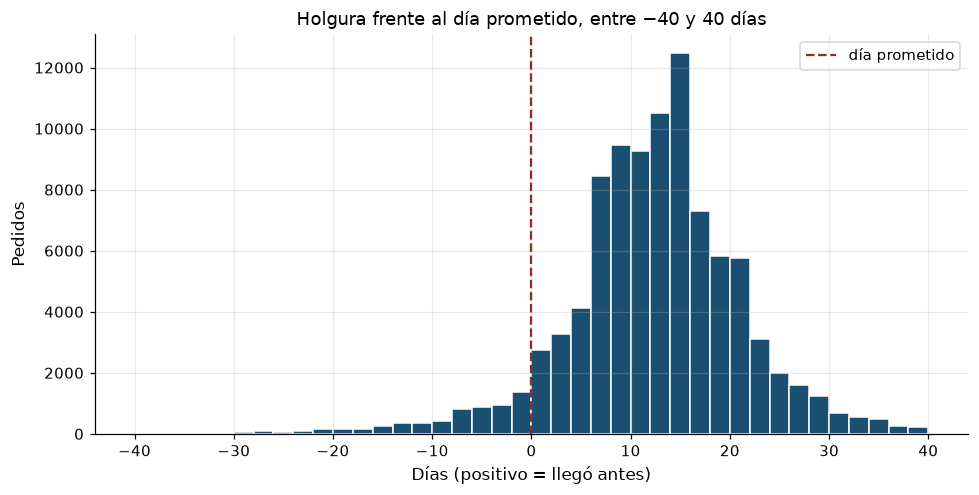

**726** pedidos quedan fuera de la ventana del histograma (holgura de **-188** a **147** días).

,pedidos,espera,promesa,tarde
tramo_promesa,,,,
hasta 7,1260,3.727,5.0,0.169
8 a 14,10742,5.004,12.0,0.050
15 a 21,23305,7.999,19.0,0.074
22 a 28,34847,11.242,25.0,0.076
29 a 45,24449,14.276,33.0,0.056
46 o más,1873,17.171,51.0,0.018


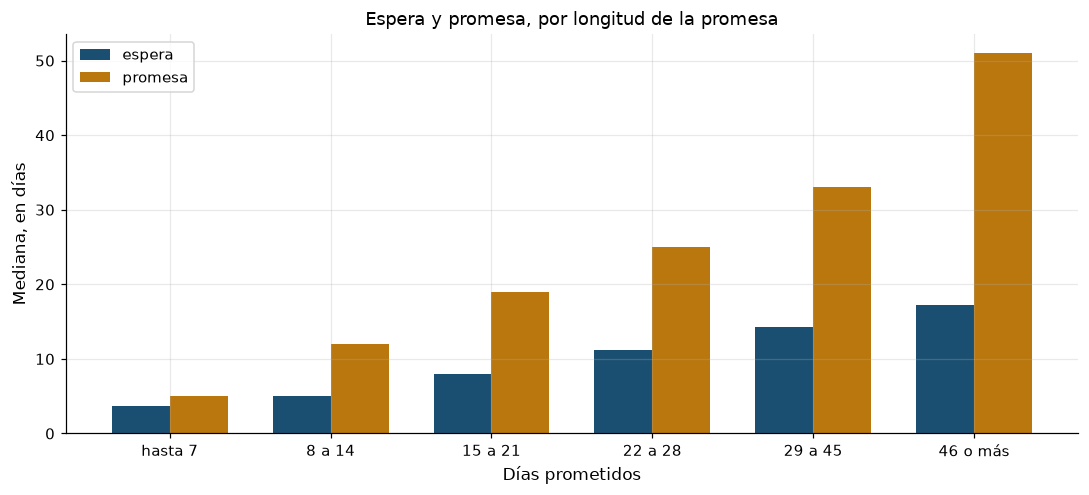

,pedidos,espera,promesa,holgura,tarde
region,,,,,
Sudeste,66198,8.710,22.0,12.0,0.061
Sul,13814,12.119,26.0,14.0,0.059
Centro-Oeste,5624,13.279,27.0,13.0,0.065
Nordeste,9044,17.320,31.0,13.0,0.127
Norte,1796,20.157,37.0,17.0,0.086


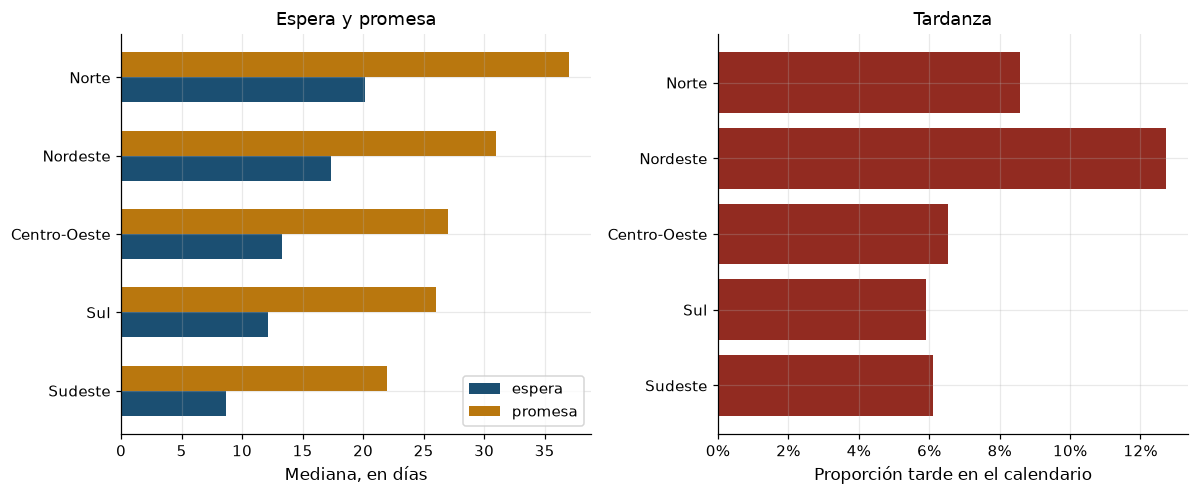

El Norte espera más y también le prometen más: la holgura mediana sigue siendo positiva. La tardanza más alta de estas cinco regiones está en **Nordeste** (12.7%), no en la región de espera más larga.

In [ ]:
en_el_dia = con["holgura_dias"].eq(0)
antes = con["holgura_dias"].gt(0)
display(Markdown(
    f"De **{len(con):,}** entregas fechadas, **{antes.mean():.1%}** llegaron antes del día prometido, "
    f"**{en_el_dia.mean():.1%}** ese día y **{con['tarde'].mean():.1%}** después. "
    f"La holgura mediana es **{con['holgura_dias'].median():.0f}** días. "
    f"El error absoluto medio es **{con['holgura_dias'].abs().mean():.1f}** días: "
    f"**{con.loc[antes, 'holgura_dias'].mean():.1f}** entre las que se adelantan y "
    f"**{(-con.loc[con['tarde'], 'holgura_dias']).mean():.1f}** entre las que se atrasan."
))

fig, ax = figura("Holgura frente al día prometido, entre −40 y 40 días", "Días (positivo = llegó antes)", "Pedidos")
en_ventana = con["holgura_dias"].between(-40, 40)
ax.hist(con.loc[en_ventana, "holgura_dias"], bins=40, color="#1b4f72", edgecolor="white")
ax.axvline(0, color="#922b21", linestyle="--", label="día prometido")
ax.legend()
fig.tight_layout()
plt.show()
display(Markdown(
    f"**{(~en_ventana).sum():,}** pedidos quedan fuera de la ventana del histograma "
    f"(holgura de **{con['holgura_dias'].min():.0f}** a **{con['holgura_dias'].max():.0f}** días)."
))

con["tramo_promesa"] = pd.cut(
    con["dias_prometidos"],
    bins=[0, 7, 14, 21, 28, 45, 400],
    labels=["hasta 7", "8 a 14", "15 a 21", "22 a 28", "29 a 45", "46 o más"],
)
calibracion = con.groupby("tramo_promesa", observed=True).agg(
    pedidos=("espera_dias", "size"),
    espera=("espera_dias", "median"),
    promesa=("dias_prometidos", "median"),
    tarde=("tarde", "mean"),
)
display(calibracion.round(3))

fig, ax = figura("Espera y promesa, por longitud de la promesa", "Días prometidos", "Mediana, en días", ancho=10)
posiciones = np.arange(len(calibracion))
ax.bar(posiciones - 0.18, calibracion["espera"], width=0.36, color="#1b4f72", label="espera")
ax.bar(posiciones + 0.18, calibracion["promesa"], width=0.36, color="#b9770e", label="promesa")
ax.set_xticks(posiciones, calibracion.index.astype(str))
ax.legend()
fig.tight_layout()
plt.show()

por_region = con.groupby("region").agg(
    pedidos=("espera_dias", "size"),
    espera=("espera_dias", "median"),
    promesa=("dias_prometidos", "median"),
    holgura=("holgura_dias", "median"),
    tarde=("tarde", "mean"),
).sort_values("espera")
display(por_region.round(3))

fig, ejes = plt.subplots(1, 2, figsize=(11, 4.6))
FIGURAS.append("Espera, promesa y tardanza por región")
ejes[0].barh(np.arange(len(por_region)) - 0.16, por_region["espera"], height=0.32, color="#1b4f72", label="espera")
ejes[0].barh(np.arange(len(por_region)) + 0.16, por_region["promesa"], height=0.32, color="#b9770e", label="promesa")
ejes[0].set_yticks(np.arange(len(por_region)), por_region.index.astype(str))
ejes[0].set_xlabel("Mediana, en días")
ejes[0].set_title("Espera y promesa")
ejes[0].legend()
ejes[1].barh(por_region.index.astype(str), por_region["tarde"], color="#922b21")
ejes[1].set_xlabel("Proporción tarde en el calendario")
ejes[1].set_title("Tardanza")
ejes[1].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _p: f"{v:.0%}"))
fig.tight_layout()
plt.show()
display(Markdown(
    "El Norte espera más y también le prometen más: la holgura mediana sigue siendo positiva. "
    f"La tardanza más alta de estas cinco regiones está en **{por_region['tarde'].idxmax()}** "
    f"({por_region['tarde'].max():.1%}), no en la región de espera más larga."
))
# El Norte espera más y también le prometen más: la holgura mediana sigue siendo positiva. La tardanza más alta de estas cinco regiones está en Nordeste (12.7%), no en la región de espera más larga.

## 6. La nota sigue el incumplimiento de la promesa

El cruce usa pedidos con una sola nota distinta. La correlación de Pearson es la que reportan los análisis públicos; con una nota de 1 a 5 también se calcula Spearman, que mira el orden y no la distancia entre un 1 y un 5. Ninguna de las dos sustituye a las medias por grupo: la relación no es una recta. Bajar la nota de 4.3 a 4.1 a lo largo de la espera es otra cosa que caer por debajo de 3 al pasar el día prometido.

Como comprobación de la definición, se recalcula la media de la nota marcando como tarde cualquier entrega posterior a la medianoche del día prometido. Ese criterio mete en el grupo tarde los paquetes que llegaron durante el día prometido.


,Pearson,Spearman
relación,,
"Espera, días",-0.334,-0.234
"Atraso de calendario, días",-0.267,-0.176
"Flete del pedido, BRL",-0.089,-0.088
"Precio de los artículos, BRL",-0.035,-0.029


Pedidos con una sola reseña: **95,641**. Se apartaron **189** con reseña en conflicto y **646** sin reseña.

,pedidos,nota
faixa,,
8 días o más tarde,2774,1.70
1 a 7 días tarde,3595,2.72
el día prometido,1273,4.04
1 a 7 días antes,17200,4.20
8 días o más antes,70799,4.32


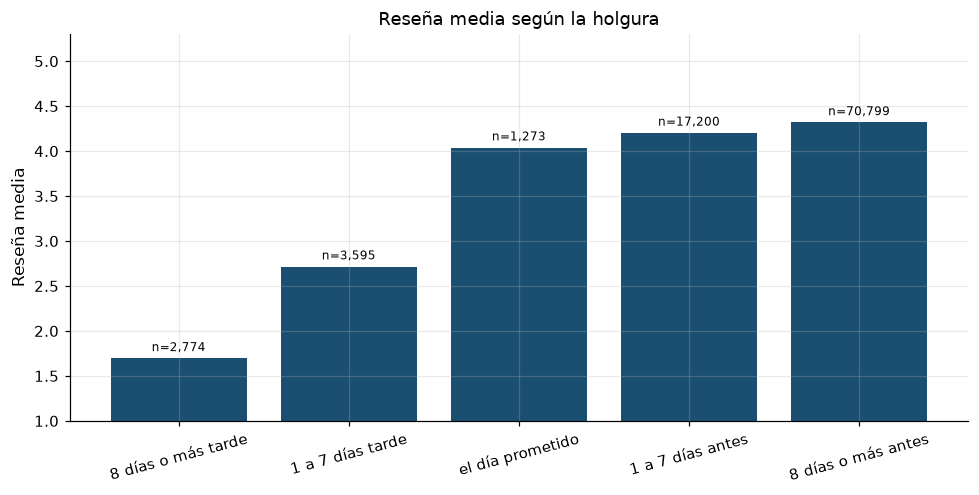

pedidos  nota
tramo_espera tarde               
hasta 7      False    25844  4.42
             True        58  3.98
7 a 14       False    39612  4.32
             True       313  3.35
14 a 22      False    18300  4.17
             True       707  2.97
más de 22    False     5516  3.88
             True      5291  2.10

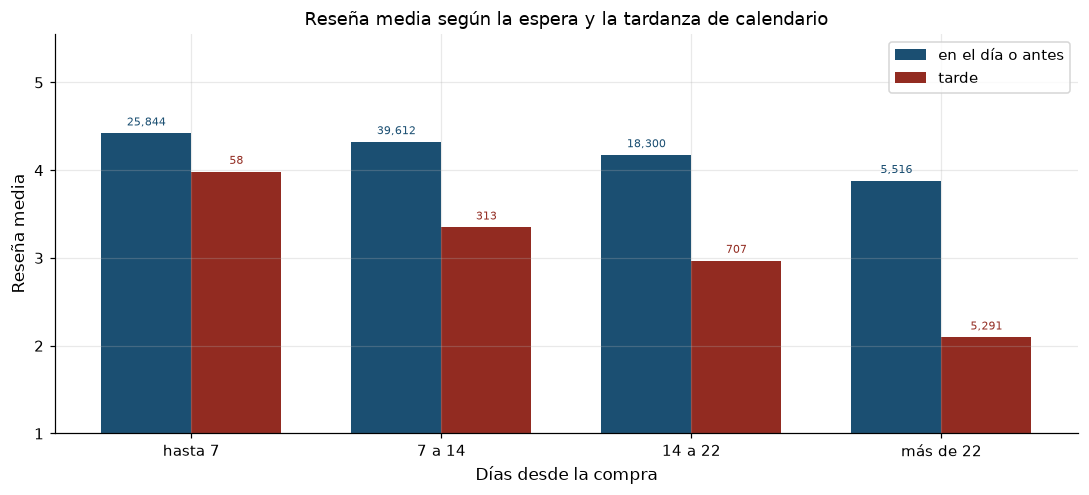

Los pedidos tarde son **6.7%** de los que tienen nota y aportan **37%** de las notas 1. Reseña media con el calendario: **4.29** a tiempo y **2.27** tarde. Con el reloj, el grupo tarde pasa a **2.57**, porque absorbe las entregas del propio día prometido. En el tramo de hasta 7 días hay **58** pedidos tarde: la barra existe, y el grupo es pequeño porque una promesa de varias semanas casi no se vence en la primera semana.

In [29]:
con_nota = con.loc[con["n_notas"].eq(1)].copy()
con_nota["atraso_dias"] = -con_nota["holgura_dias"]
pares = {
    "Espera, días": con_nota["espera_dias"],
    "Atraso de calendario, días": con_nota["atraso_dias"],
    "Flete del pedido, BRL": con_nota["flete"],
    "Precio de los artículos, BRL": con_nota["precio"],
}
filas = []
for nombre, serie in pares.items():
    filas.append({
        "relación": nombre,
        "Pearson": coef(stats.pearsonr, serie, con_nota["nota"]),
        "Spearman": coef(stats.spearmanr, serie, con_nota["nota"]),
    })
correlacion = pd.DataFrame(filas).set_index("relación")
display(correlacion.round(3))
display(Markdown(
    f"Pedidos con una sola reseña: **{len(con_nota):,}**. "
    f"Se apartaron **{int(con['n_notas'].gt(1).sum()):,}** con reseña en conflicto y "
    f"**{int(con['nota'].isna().sum()):,}** sin reseña."
))

con_nota["faixa"] = pd.cut(
    con_nota["holgura_dias"],
    bins=[-10**9, -8, -1, 0, 7, 10**9],
    labels=[
        "8 días o más tarde",
        "1 a 7 días tarde",
        "el día prometido",
        "1 a 7 días antes",
        "8 días o más antes",
    ],
)
por_faixa = con_nota.groupby("faixa", observed=True)["nota"].agg(pedidos="size", nota="mean")
display(por_faixa.round(2))
fig, ax = figura("Reseña media según la holgura", "", "Reseña media")
ax.bar(por_faixa.index.astype(str), por_faixa["nota"], color="#1b4f72")
ax.set_ylim(1, 5.3)
ax.tick_params(axis="x", labelrotation=15)
for i, fila in enumerate(por_faixa.itertuples()):
    ax.text(i, fila.nota + 0.08, f"n={fila.pedidos:,}", ha="center", fontsize=8)
fig.tight_layout()
plt.show()

con_nota["tramo_espera"] = pd.cut(
    con_nota["espera_dias"],
    bins=[0, 7, 14, 22, 400],
    labels=["hasta 7", "7 a 14", "14 a 22", "más de 22"],
)
por_cruce = con_nota.groupby(["tramo_espera", "tarde"], observed=True)["nota"].agg(pedidos="size", nota="mean")
display(por_cruce.round(2))
fig, ax = figura("Reseña media según la espera y la tardanza de calendario", "Días desde la compra", "Reseña media", ancho=10)
tramos_espera = por_cruce.index.get_level_values(0).unique()
posiciones = np.arange(len(tramos_espera))
a_tiempo = por_cruce.xs(False, level="tarde").reindex(tramos_espera)
tarde = por_cruce.xs(True, level="tarde").reindex(tramos_espera)
ax.bar(posiciones - 0.18, a_tiempo["nota"], width=0.36, color="#1b4f72", label="en el día o antes")
ax.bar(posiciones + 0.18, tarde["nota"], width=0.36, color="#922b21", label="tarde")
ax.set_xticks(posiciones, tramos_espera.astype(str))
ax.set_ylim(1, 5.55)
for i, fila in enumerate(a_tiempo.itertuples()):
    ax.text(i - 0.18, fila.nota + 0.06, f"{int(fila.pedidos):,}", ha="center", va="bottom", fontsize=7, color="#1b4f72")
for i, fila in enumerate(tarde.itertuples()):
    ax.text(i + 0.18, fila.nota + 0.06, f"{int(fila.pedidos):,}", ha="center", va="bottom", fontsize=7, color="#922b21")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()

una_estrella = con_nota["nota"].eq(1)
tarde_reloj = con_nota["order_delivered_customer_date"].gt(con_nota["order_estimated_delivery_date"])
media_calendario = con_nota.groupby("tarde")["nota"].mean()
media_reloj = con_nota.groupby(tarde_reloj)["nota"].mean()
display(Markdown(
    f"Los pedidos tarde son **{con_nota['tarde'].mean():.1%}** de los que tienen nota y aportan "
    f"**{con_nota.loc[una_estrella, 'tarde'].mean():.0%}** de las notas 1. "
    f"Reseña media con el calendario: **{media_calendario.loc[False]:.2f}** a tiempo y **{media_calendario.loc[True]:.2f}** tarde. "
    f"Con el reloj, el grupo tarde pasa a **{media_reloj.loc[True]:.2f}**, porque absorbe las entregas del propio día prometido. "
    f"En el tramo de hasta 7 días hay **{int(tarde.loc['hasta 7', 'pedidos']):,}** pedidos tarde: "
    "la barra existe, y el grupo es pequeño porque una promesa de varias semanas casi no se vence en la primera semana."
))


## 7. El límite del vendedor y el estado compartido

`shipping_limit_date` es la hora límite para que el vendedor entregue la línea al transportista, no el día que ve el cliente. Como la hora está guardada, aquí el incumplimiento del vendedor compara relojes: el transportista recibió el pedido después del límite de la última línea. La tardanza del cliente sigue siendo de calendario.

El estado compartido usa pedidos de un solo vendedor. Es un sustituto grueso de la distancia: no hay kilómetros en este cruce. São Paulo concentra clientes y vendedores, así que el gráfico separa a los clientes de ese estado del resto.


En **96,475** pedidos con límite y con entrega al transportista, el vendedor se pasa de esa hora en **9.0%**. Si la cumplió, el cliente llega tarde el **5.4%** de las veces; si no la cumplió, el **20.8%**. Entre los clientes que llegan tarde, el vendedor había cumplido el límite en **72%** de los pedidos.

pedidos  espera  tarde  promesa
cliente_en_SP mismo_estado                                 
False         False           51350  13.333  0.089     27.0
              True             3923   6.544  0.034     20.0
True          False            9615   9.722  0.041     25.0
              True            30313   6.592  0.047     18.0

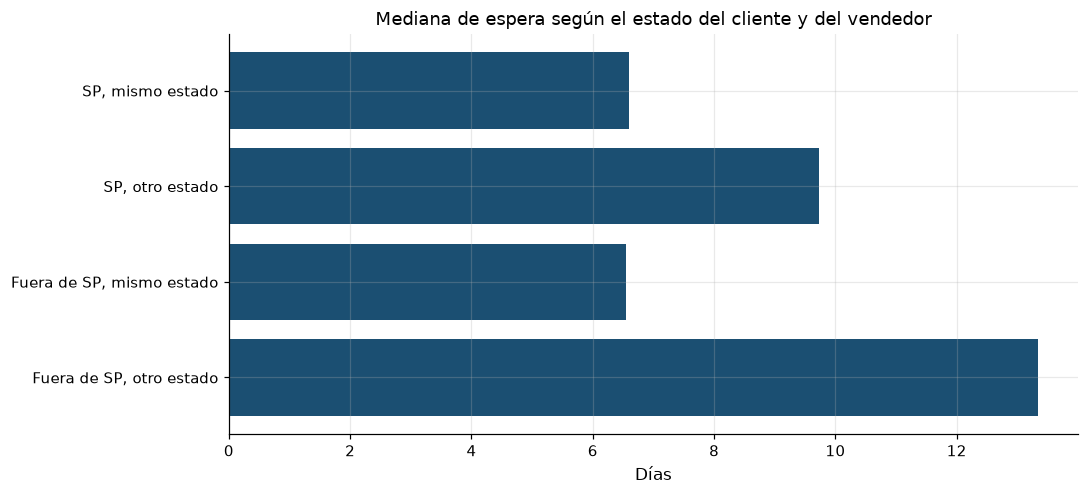

Pedidos de un solo vendedor: **95,201**. Compartir estado baja la mediana de **13.3** a **6.5** días fuera de São Paulo, y de **9.7** a **6.6** dentro.

In [26]:
despacho = con.loc[con["limite_despacho"].notna() & con["order_delivered_carrier_date"].notna()].copy()
despacho["vendedor_tarde"] = despacho["order_delivered_carrier_date"].gt(despacho["limite_despacho"])
display(Markdown(
    f"En **{len(despacho):,}** pedidos con límite y con entrega al transportista, "
    f"el vendedor se pasa de esa hora en **{despacho['vendedor_tarde'].mean():.1%}**. "
    f"Si la cumplió, el cliente llega tarde el **{despacho.loc[~despacho['vendedor_tarde'], 'tarde'].mean():.1%}** de las veces; "
    f"si no la cumplió, el **{despacho.loc[despacho['vendedor_tarde'], 'tarde'].mean():.1%}**. "
    f"Entre los clientes que llegan tarde, el vendedor había cumplido el límite en "
    f"**{(~despacho.loc[despacho['tarde'], 'vendedor_tarde']).mean():.0%}** de los pedidos."
))

un_vendedor = con.loc[con["n_vendedores"].eq(1) & con["estado_vendedor"].notna()].copy()
un_vendedor["mismo_estado"] = un_vendedor["estado_vendedor"].eq(un_vendedor["customer_state"])
un_vendedor["en_sp"] = un_vendedor["customer_state"].eq("SP")
por_lugar = un_vendedor.groupby(["en_sp", "mismo_estado"]).agg(
    pedidos=("espera_dias", "size"),
    espera=("espera_dias", "median"),
    tarde=("tarde", "mean"),
    promesa=("dias_prometidos", "median"),
)
por_lugar.index = por_lugar.index.set_names(["cliente_en_SP", "mismo_estado"])
display(por_lugar.round(3))

orden_lugar = [(True, True), (True, False), (False, True), (False, False)]
etiquetas = [
    "SP, mismo estado",
    "SP, otro estado",
    "Fuera de SP, mismo estado",
    "Fuera de SP, otro estado",
]
fig, ax = figura("Mediana de espera según el estado del cliente y del vendedor", "Días", "", ancho=10)
ax.barh(etiquetas[::-1], [por_lugar.loc[clave, "espera"] for clave in orden_lugar][::-1], color="#1b4f72")
fig.tight_layout()
plt.show()
display(Markdown(
    f"Pedidos de un solo vendedor: **{len(un_vendedor):,}**. "
    f"Compartir estado baja la mediana de **{por_lugar.loc[(False, False), 'espera']:.1f}** a "
    f"**{por_lugar.loc[(False, True), 'espera']:.1f}** días fuera de São Paulo, y de "
    f"**{por_lugar.loc[(True, False), 'espera']:.1f}** a **{por_lugar.loc[(True, True), 'espera']:.1f}** dentro."
))


## 8. Mayo de 2018

El paro de camioneros fue del 21 al 30 de mayo de 2018. La ventana de compra «antes» son los 30 días previos y la ventana «después» los 30 días siguientes. El gráfico semanal usa la semana de la compra y se queda en 2018, dentro de los meses en los que el volumen ya es estable. Una compra hecha justo antes del paro puede haber viajado durante el paro: la fecha de compra no es la fecha en carretera.


,pedidos,espera,promesa,holgura,tarde
ventana,,,,,
antes,7483,8.859,22.0,12.0,0.065
huelga,1370,12.181,28.0,16.5,0.028
despues,6105,7.975,28.0,20.0,0.012


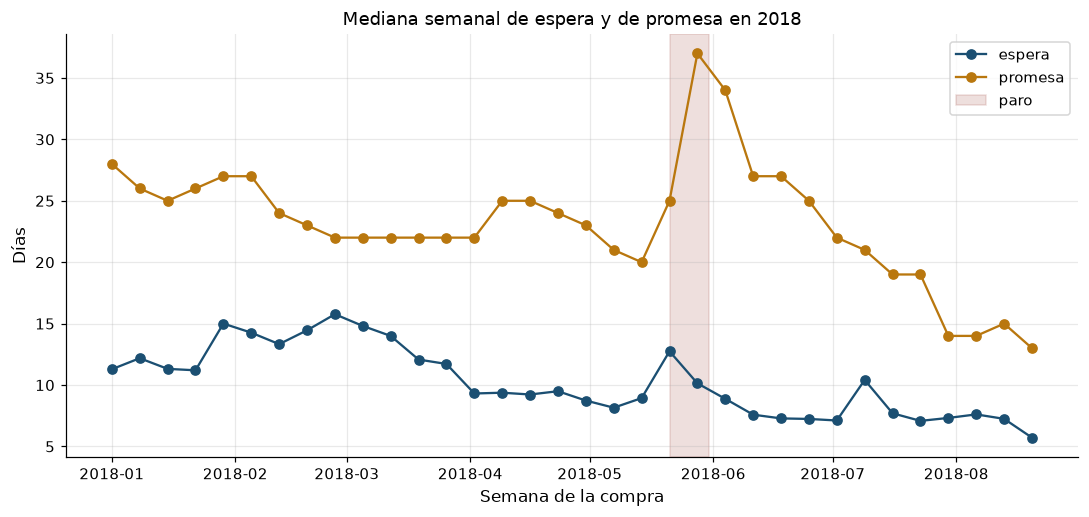

En las compras del paro la espera mediana pasa de **8.9** a **12.2** días y la promesa mediana de **22** a **28**. La tardanza de calendario baja de **6.5%** a **2.8%**. En los 30 días siguientes la espera mediana es **8.0** y la promesa sigue en **28**.

In [27]:
dia_compra = con["order_purchase_timestamp"].dt.normalize()
ventana = pd.Series(pd.NA, index=con.index, dtype="string")
ventana.loc[dia_compra.between("2018-04-21", "2018-05-20")] = "antes"
ventana.loc[dia_compra.between("2018-05-21", "2018-05-30")] = "huelga"
ventana.loc[dia_compra.between("2018-05-31", "2018-06-29")] = "despues"
con["ventana"] = pd.Categorical(ventana, categories=["antes", "huelga", "despues"], ordered=True)
ventanas = con.groupby("ventana", observed=True).agg(
    pedidos=("espera_dias", "size"),
    espera=("espera_dias", "median"),
    promesa=("dias_prometidos", "median"),
    holgura=("holgura_dias", "median"),
    tarde=("tarde", "mean"),
)
display(ventanas.round(3))

con["semana"] = con["order_purchase_timestamp"].dt.to_period("W-SUN").dt.start_time
por_semana = con.groupby("semana").agg(
    pedidos=("espera_dias", "size"),
    espera=("espera_dias", "median"),
    promesa=("dias_prometidos", "median"),
)
serie = por_semana.loc["2018-01-01":"2018-08-20"]
serie = serie.loc[serie["pedidos"].ge(200)]
fig, ax = figura("Mediana semanal de espera y de promesa en 2018", "Semana de la compra", "Días", ancho=10, alto=4.8)
ax.plot(serie.index, serie["espera"], color="#1b4f72", marker="o", label="espera")
ax.plot(serie.index, serie["promesa"], color="#b9770e", marker="o", label="promesa")
ax.axvspan(pd.Timestamp("2018-05-21"), pd.Timestamp("2018-05-31"), color="#922b21", alpha=0.15, label="paro")
ax.legend()
fig.tight_layout()
plt.show()
display(Markdown(
    f"En las compras del paro la espera mediana pasa de **{ventanas.loc['antes', 'espera']:.1f}** a "
    f"**{ventanas.loc['huelga', 'espera']:.1f}** días y la promesa mediana de "
    f"**{ventanas.loc['antes', 'promesa']:.0f}** a **{ventanas.loc['huelga', 'promesa']:.0f}**. "
    f"La tardanza de calendario baja de **{ventanas.loc['antes', 'tarde']:.1%}** a "
    f"**{ventanas.loc['huelga', 'tarde']:.1%}**. "
    f"En los 30 días siguientes la espera mediana es **{ventanas.loc['despues', 'espera']:.1f}** "
    f"y la promesa sigue en **{ventanas.loc['despues', 'promesa']:.0f}**."
))


## 9. Lectura

La espera mediana es de 10.2 días y la media, de 12.6. Esa media se reparte en una aprobación cuya mediana es de 20 minutos y cuya media sube a 9.7 horas por una cola, 2.9 días de media hasta que el vendedor entrega al transportista y 9.4 días de tránsito. Las medianas no suman la mediana de la espera: son 20 minutos, 1.8 días y 7.1 días. El tránsito se queda con el 86% de la varianza de los tramos y con el 83% de la diferencia de espera entre las notas 1–2 y las notas 4–5. El cuello de la espera, en este extracto, está después de que el vendedor soltó el paquete. Cuando el vendedor se pasa de su límite la tardanza del cliente sube, y aun así la mayoría de los clientes que llegan tarde habían tenido un vendedor dentro del límite.

La promesa mediana es de 24 días. La holgura mediana, el día prometido menos el día de entrega, es de 12 días: no es la resta de las dos medianas. El 91.9% llega antes del día prometido, el 1.3% ese día y el 6.8% después. El error absoluto medio es de 13.3 días. Alargar la promesa alarga el margen: en el tramo de promesas de hasta 7 días la tardanza es la más alta de la tabla, y en el de 46 días o más es la más baja. El Norte espera cerca de 20 días y le prometen cerca de 37; el Nordeste espera menos que el Norte e incumple más. Compartir estado el cliente y el único vendedor acorta la mediana tanto dentro como fuera de São Paulo.

La nota media es 4.29 si el paquete llegó en el día prometido o antes, y 2.27 si llegó después. Ocho días o más de adelanto quedan en 4.32; ocho días o más de atraso, en 1.70. Pearson de la espera con la nota es −0.33 y el del atraso es −0.27; el del flete es −0.09 y el del precio, −0.03. Dentro de cada tramo de espera, la barra tarde queda por debajo de la barra a tiempo, y la distancia entre las dos crece cuando la espera ya es larga. Los pedidos tarde son el 6.7% de los que tienen nota y el 37% de las notas 1. Marcar como tarde el reloj, en lugar del día, sube la nota media de ese grupo: las entregas del propio día prometido no se parecen a las tardías.

En las compras del 21 al 30 de mayo de 2018 la espera mediana sube de 8.9 a 12.2 días y la promesa mediana de 22 a 28. La tardanza baja de 6.5% a 2.8%. En los 30 días siguientes la espera queda por debajo del tramo previo y la promesa sigue en 28. Lo que se mueve en el indicador de tardanza es la fecha prometida.

| Lectura que circula sobre este conjunto | Qué se sostiene en este extracto |
| --- | --- |
| El tránsito concentra la espera y la brecha entre notas | La media del tránsito es el tramo largo; su parte de la varianza supera el 80%, y también la de la brecha entre notas 1–2 y 4–5. |
| La promesa es holgada y el atraso ronda el 7% | Holgura mediana de 12 días, 6.8% tarde por calendario, error absoluto medio de 13.3 días. |
| La nota cae con la logística y casi no con el monto | Pearson −0.33 y −0.27 frente a −0.09 del flete. La caída fuerte aparece al pasar el día prometido. |
| En mayo de 2018 se movió la promesa | La espera sube unos 3 días y la promesa unos 6; el porcentaje de tardanzas baja. |


## 10. Validación


In [28]:
assert pedidos["order_id"].is_unique
assert len(base) == len(pedidos) == 99441
assert base["customer_state"].notna().all()
assert set(pedidos["order_estimated_delivery_date"].dt.hour.unique()) == {0}
assert articulos["shipping_limit_date"].dt.hour.nunique() > 1
assert (~pedidos["order_id"].isin(articulos["order_id"])).sum() > 500
assert int(con["n_notas"].gt(1).sum()) > 100
assert (con["espera_dias"] < 0).sum() == 0
assert (con["tramo_vendedor"] < 0).sum() > 1000
assert (con["tramo_transito"] < 0).sum() > 0
assert con["region"].notna().all()

assert 9 < con["espera_dias"].median() < 12
assert con["dias_prometidos"].median() >= 20
assert con["holgura_dias"].median() >= 10
assert 0.06 < con["tarde"].mean() < 0.08
assert (con["holgura_dias"] > 0).mean() > 0.90
assert validos[TRAMOS].mean().sum() == validos["espera_dias"].mean() or np.isclose(
    validos[TRAMOS].mean().sum(), validos["espera_dias"].mean()
)
assert validos["tramo_transito"].median() > validos["tramo_vendedor"].median() > validos["tramo_aprobacion"].median()
assert participacion.loc["Transportista al cliente"] > 0.80
assert parte_brecha.loc["Transportista al cliente"] > 0.75

assert correlacion.loc["Espera, días", "Pearson"] < -0.30
assert correlacion.loc["Atraso de calendario, días", "Pearson"] < -0.20
assert abs(correlacion.loc["Flete del pedido, BRL", "Pearson"]) < abs(correlacion.loc["Espera, días", "Pearson"]) / 2
assert con_nota.groupby("tarde")["nota"].mean().loc[True] < con_nota.groupby("tarde")["nota"].mean().loc[False] - 1.5
assert con_nota.loc[con_nota["nota"].eq(1), "tarde"].mean() > 0.30

assert por_region.loc["Norte", "espera"] > por_region.loc["Sudeste", "espera"]
assert por_region.loc["Norte", "promesa"] > por_region.loc["Norte", "espera"]
assert por_region.loc["Nordeste", "tarde"] > por_region.loc["Sudeste", "tarde"]
assert calibracion["promesa"].is_monotonic_increasing
assert (calibracion["promesa"] > calibracion["espera"]).all()

assert (~despacho["vendedor_tarde"]).mean() > 0.85
assert despacho.loc[despacho["tarde"], "vendedor_tarde"].mean() < 0.40
assert por_lugar.loc[(False, True), "espera"] < por_lugar.loc[(False, False), "espera"]
assert por_lugar.loc[(True, True), "espera"] < por_lugar.loc[(True, False), "espera"]

assert ventanas.loc["huelga", "espera"] > ventanas.loc["antes", "espera"]
assert ventanas.loc["huelga", "promesa"] > ventanas.loc["antes", "promesa"]
assert ventanas.loc["huelga", "tarde"] < ventanas.loc["antes", "tarde"]
assert ventanas.loc["huelga", "promesa"] - ventanas.loc["antes", "promesa"] > (
    ventanas.loc["huelga", "espera"] - ventanas.loc["antes", "espera"]
)

assert len(FIGURAS) >= 8
print("VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.")
print("Figuras:", len(FIGURAS))
for titulo in FIGURAS:
    print("-", titulo)


VALIDACIÓN: las comprobaciones de este cuaderno se cumplieron.
Figuras: 9
- Espera desde la compra, hasta el percentil 99
- Mediana de cada tramo, con las fechas en orden
- Holgura frente al día prometido, entre −40 y 40 días
- Espera y promesa, por longitud de la promesa
- Espera, promesa y tardanza por región
- Nota media según la holgura
- Nota media según la espera y la tardanza de calendario
- Mediana de espera según el estado del cliente y del vendedor
- Mediana semanal de espera y de promesa en 2018


## 11. Alcance

La nota y la tardanza se observan juntas. El texto de la reseña, que podría separar un atraso de un producto dañado, está en otro cuaderno. El estado compartido no es una distancia: dos ciudades del mismo estado pueden quedar lejos, y un vendedor de Minas Gerais puede estar cerca de un cliente de São Paulo.

El límite de despacho se resume con el máximo de las líneas. Un pedido de varios vendedores puede tener una línea a tiempo y otra no; el indicador del pedido mira la última. La comparación de estados usa solo pedidos de un vendedor.

Las ventanas de mayo de 2018 cortan por la fecha de compra. No reconstruyen qué paquetes estaban en la ruta los días del paro. Los meses de los extremos del extracto no entran en la serie semanal. Las inversiones de fecha y las esperas extremas se conservan; no hay una regla que las reescriba o las recorte de las tasas.
